#Network Intrusion Detection and Anomaly Intelligence System

In [ ]:
import os
import glob

files = glob.glob('/content/*.csv')

print("Total CSV Files:", len(files))

for file in files:
    print(os.path.basename(file))

Total CSV Files: 8
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv


In [ ]:
import pandas as pd
import glob
import os

files = glob.glob('/content/*.csv')

dataframes = []

for file in files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.str.strip()
    dataframes.append(temp)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset Combined Successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Combined Successfully!
Total Rows: 1570675
Total Columns: 79


Data inspection

In [ ]:
df.head(2)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,166,1,1,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,60148,83,1,2,0,0,0,0,0.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
df.tail(2)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
2830741,53,1048635,6,2,192,256,32,32,32.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830742,53,94939,4,2,188,226,47,47,47.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  

In [ ]:
df.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,...,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06
mean,8.071483e+03,1.478566e+07,9.361160e+00,1.039377e+01,5.493024e+02,1.616264e+04,2.075999e+02,1.871366e+01,5.820194e+01,6.891013e+01,...,5.418218e+00,-2.741688e+03,8.155132e+04,4.113412e+04,1.531825e+05,5.829582e+04,8.316037e+06,5.038439e+05,8.695752e+06,7.920031e+06
std,1.828363e+04,3.365374e+07,7.496728e+02,9.973883e+02,9.993589e+03,2.263088e+06,7.171848e+02,6.033935e+01,1.860912e+02,2.811871e+02,...,6.364257e+02,1.084989e+06,6.485999e+05,3.933815e+05,1.025825e+06,5.770923e+05,2.363008e+07,4.602984e+06,2.436689e+07,2.336342e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,1.550000e+02,2.000000e+00,1.000000e+00,1.200000e+01,0.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,3.131600e+04,2.000000e+00,2.000000e+00,6.200000e+01,1.230000e+02,3.700000e+01,2.000000e+00,3.400000e+01,0.000000e+00,...,1.000000e+00,2.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,3.204828e+06,5.000000e+00,4.000000e+00,1.870000e+02,4.820000e+02,8.100000e+01,3.600000e+01,5.000000e+01,2.616295e+01,...,2.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


In [ ]:
df.shape

(2830743, 79)

In [ ]:
df.dtypes

,0
Destination Port,int64
Flow Duration,int64
Total Fwd Packets,int64
Total Backward Packets,int64
Total Length of Fwd Packets,int64
...,...
Idle Mean,float64
Idle Std,float64
Idle Max,int64
Idle Min,int64


In [ ]:
df.isnull().sum().sum()

np.int64(1358)

In [ ]:
df.duplicated().sum()

np.int64(308381)

In [ ]:
import numpy as np
print("Infinite Values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Infinite Values: 4376


Data cleaning

In [ ]:
# Clean Column Names
df.columns = df.columns.str.strip()


In [ ]:
# Replace infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [ ]:
# Remove Duplicate Records
df.drop_duplicates(inplace=True)

In [ ]:
# Remove rows with missing labels
df.dropna(subset=['Label'], inplace=True)

In [ ]:
# Handle missing numeric values
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())


In [ ]:
df.shape

(2522362, 79)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

Exploratory Data Analysis (EDA)

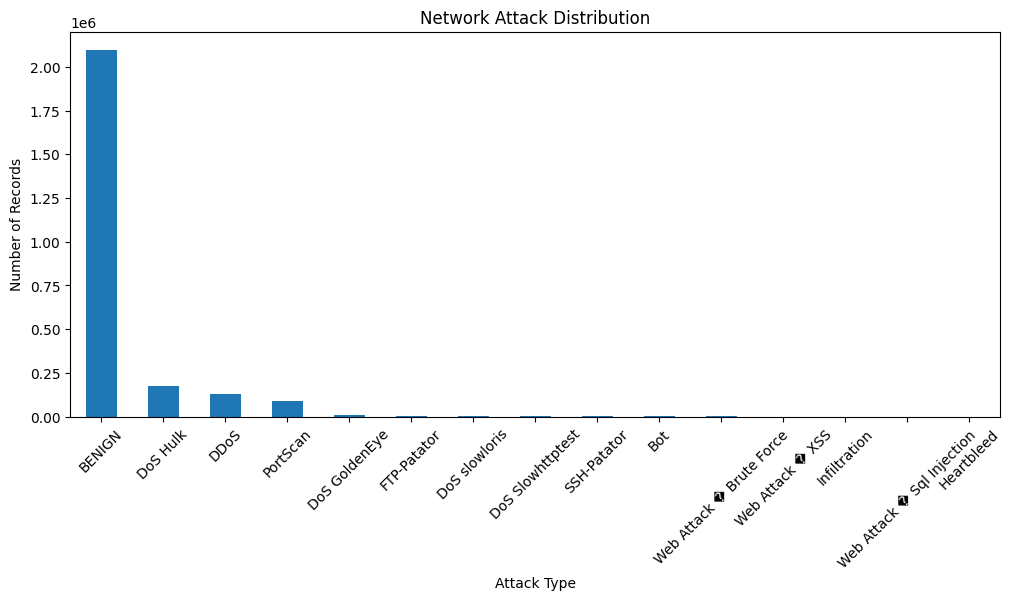

In [ ]:
#Univariate Analysis
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5))

df['Label'].value_counts().plot(kind='bar')

plt.title('Network Attack Distribution')
plt.xlabel('Attack Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)

plt.show()

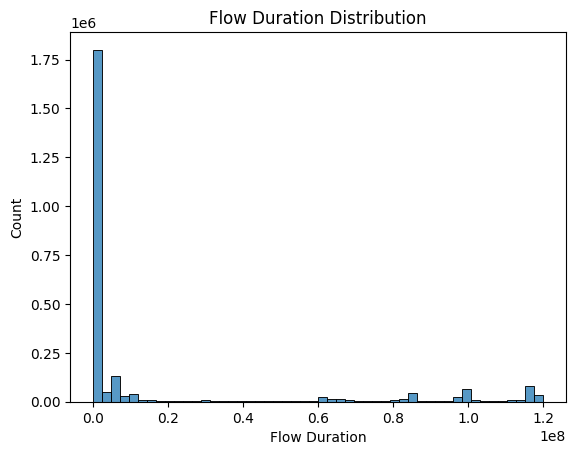

In [ ]:
sns.histplot(df['Flow Duration'], bins=50)
plt.title('Flow Duration Distribution')
plt.show()

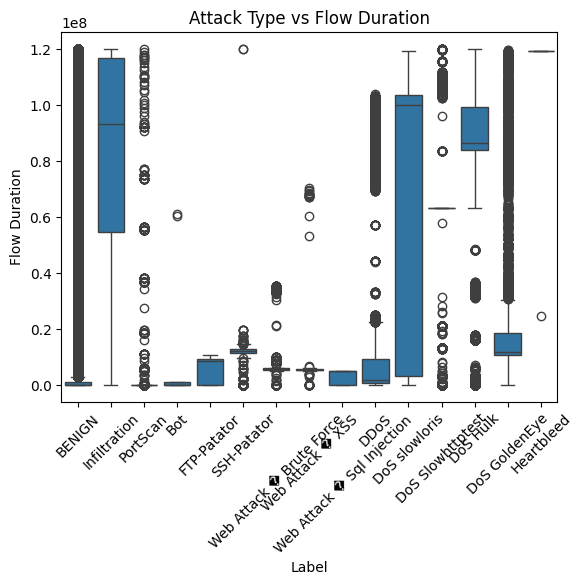

In [ ]:
#Bivariate Analysis
sns.boxplot(data=df, x='Label', y='Flow Duration')
plt.xticks(rotation=45)
plt.title('Attack Type vs Flow Duration')
plt.show()

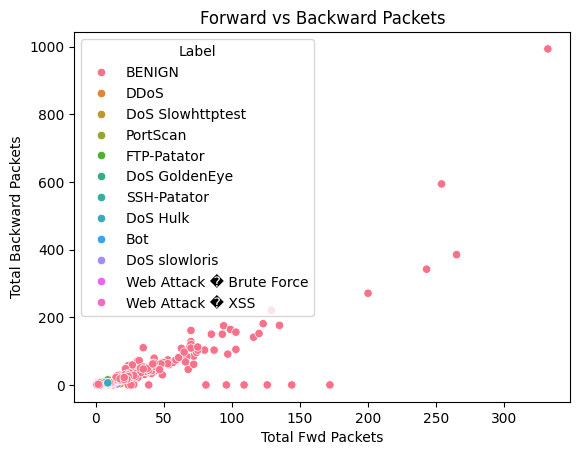

In [ ]:
sns.scatterplot(
    data=df.sample(min(5000, len(df))),
    x='Total Fwd Packets',
    y='Total Backward Packets',
    hue='Label'
)
plt.title('Forward vs Backward Packets')
plt.show()

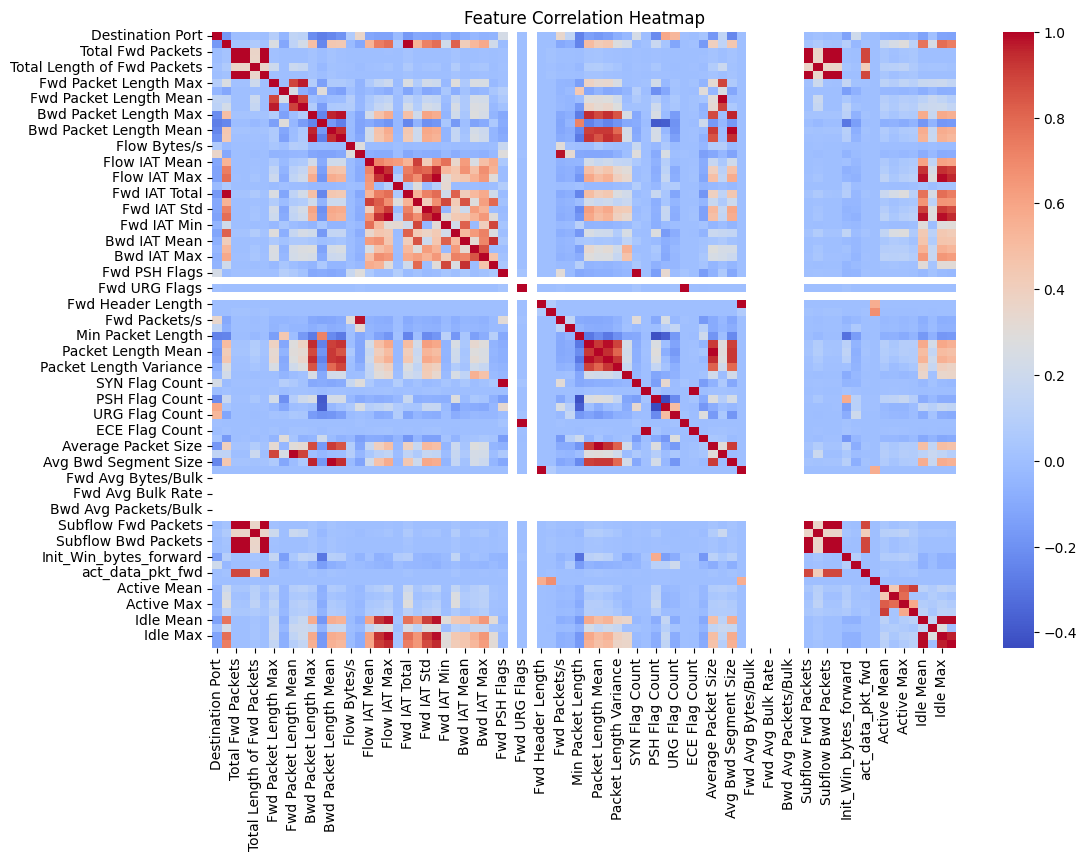

In [ ]:
#Multivariate Analysis
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap='coolwarm'
)
plt.title('Feature Correlation Heatmap')
plt.show()

Feature Engineering

In [ ]:
# Total Packets
df['Total Packets'] = (
    df['Total Fwd Packets'] + df['Total Backward Packets']
)


In [ ]:
# Total Packet Length
df['Total Packet Length'] = (
    df['Total Length of Fwd Packets'] +
    df['Total Length of Bwd Packets']
)

In [ ]:
# Average Packet Size
df['Average Packet Size'] = (
    df['Total Packet Length'] /
    df['Total Packets'].replace(0, np.nan)
)

In [ ]:
# Handle new missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

df['Average Packet Size'] = df['Average Packet Size'].fillna(0)


In [ ]:
df.shape

(2522362, 81)

Feature Selection & Data Preparation

In [ ]:
# Separate Features and Target

X = df.drop('Label', axis=1)
y = df['Label']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Target Classes:", y.nunique())

Features Shape: (2522362, 80)
Target Shape: (2522362,)
Target Classes: 15


In [ ]:
# Check data types

print("Numeric Columns:",
      X.select_dtypes(include=np.number).shape[1])

print("Non-Numeric Columns:",
      X.select_dtypes(exclude=np.number).shape[1])

print("\nNon-Numeric Column Names:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Numeric Columns: 80
Non-Numeric Columns: 0

Non-Numeric Column Names:
[]


In [ ]:
# Check missing values
print("Missing Values:", X.isnull().sum().sum())

# Check infinite values
print("Infinite Values:",
      np.isinf(X).sum().sum())

Missing Values: 0
Infinite Values: 0


In [ ]:
# Target Class Distribution

print("Attack Type Distribution:")
print(y.value_counts())

print("\nTotal Attack Classes:", y.nunique())

Attack Type Distribution:
Label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Total Attack Classes: 15


In [ ]:
# Class Imbalance Analysis

class_percentage = (y.value_counts(normalize=True) * 100)

print("Class Distribution Percentage:")
print(class_percentage.round(4))

print("\nMajority Class:", y.value_counts().idxmax())
print("Majority Percentage:",
      round(class_percentage.max(), 4), "%")

print("\nMinority Class:", y.value_counts().idxmin())
print("Minority Percentage:",
      round(class_percentage.min(), 4), "%")

Class Distribution Percentage:
Label
BENIGN                        83.1159
DoS Hulk                       6.8527
DDoS                           5.0752
PortScan                       3.6006
DoS GoldenEye                  0.4078
FTP-Patator                    0.2352
DoS slowloris                  0.2135
DoS Slowhttptest               0.2073
SSH-Patator                    0.1276
Bot                            0.0774
Web Attack � Brute Force       0.0583
Web Attack � XSS               0.0258
Infiltration                   0.0014
Web Attack � Sql Injection     0.0008
Heartbleed                     0.0004
Name: proportion, dtype: float64

Majority Class: BENIGN
Majority Percentage: 83.1159 %

Minority Class: Heartbleed
Minority Percentage: 0.0004 %


In [ ]:
from sklearn.model_selection import train_test_split

# Take a representative sample
X_sample, _, y_sample, _ = train_test_split(
    X, y,
    train_size=300000,
    stratify=y,
    random_state=42
)

print("Sample Features Shape:", X_sample.shape)
print("Sample Target Shape:", y_sample.shape)
print("\nSample Class Distribution:")
print(y_sample.value_counts())

Sample Features Shape: (300000, 80)
Sample Target Shape: (300000,)

Sample Class Distribution:
Label
BENIGN                        249348
DoS Hulk                       20558
DDoS                           15226
PortScan                       10802
DoS GoldenEye                   1223
FTP-Patator                      706
DoS slowloris                    640
DoS Slowhttptest                 622
SSH-Patator                      383
Bot                              232
Web Attack � Brute Force         175
Web Attack � XSS                  78
Infiltration                       4
Web Attack � Sql Injection         2
Heartbleed                         1
Name: count, dtype: int64


In [ ]:
# Identify classes with at least 2 records
class_counts = y_sample.value_counts()

valid_classes = class_counts[class_counts >= 2].index

In [ ]:
# Separate valid and rare classes
valid_mask = y_sample.isin(valid_classes)

X_valid = X_sample[valid_mask]
y_valid = y_sample[valid_mask]

In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_valid,
    y_valid,
    test_size=0.2,
    random_state=42,
    stratify=y_valid
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nRare Classes Excluded:")
print(class_counts[class_counts < 2])

Training Shape: (239999, 80)
Testing Shape: (60000, 80)

Rare Classes Excluded:
Label
Heartbleed    1
Name: count, dtype: int64


Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Scaled:", X_train_scaled.shape)
print("Testing Data Scaled:", X_test_scaled.shape)

Training Data Scaled: (239999, 80)
Testing Data Scaled: (60000, 80)


Random Forest Model Training

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

In [ ]:
# Train Model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!
